In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import shutil

shutil.copy('/content/drive/MyDrive/archive.zip', '/content/dataset.zip')

'/content/dataset.zip'

In [3]:
import zipfile

with zipfile.ZipFile('/content/dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('/content')

In [4]:
import os
os.listdir('/content')

['.config', 'Dataset', 'dataset.zip', 'drive', 'sample_data']

In [5]:
import pandas as pd
import numpy as np
import os

path_normal = "/content/Dataset/Normal"
path_irf = "/content/Dataset/Inner Race Fault"
path_orf = "/content/Dataset/Outer Race Fault"

def create_structured_csv(folder_path, output_name):
    all_signals = []
    files = os.listdir(folder_path)

    # Sélectionner 100 fichiers au hasard [cite: 18]
    selected_files = np.random.choice(files, 100, replace=False)

    for f in selected_files:
      file_path = os.path.join(folder_path, f)
      signal = pd.read_csv(file_path, header=None).values.flatten()

      # Garder seulement 5000 échantillons
      signal = signal[:5000]

      all_signals.append(signal)

    # Créer le DataFrame : 100 lignes (signaux) [cite: 21]
    df = pd.DataFrame(all_signals)
    df.to_csv(output_name, index=False)
    return df

df_normal = create_structured_csv(path_normal, "base_normal.csv")
df_irf = create_structured_csv(path_irf, "base_irf.csv")
df_orf = create_structured_csv(path_orf, "base_orf.csv")

In [6]:
from google.colab import data_table

data_table.enable_dataframe_formatter()

df_normal.head(30)

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
0,-0.002747,-0.003052,-0.002899,-0.003052,-0.003204,-0.003204,-0.003510,-0.003357,-0.003510,-0.003510,...,-0.003510,-0.003510,-0.003357,-0.003510,-0.003357,-0.003357,-0.003204,-0.003204,-0.003052,-0.003204
1,0.000610,0.000763,0.000763,0.001068,0.001221,0.001221,0.001221,0.001526,0.001526,0.001678,...,0.000916,0.001221,0.001221,0.001068,0.001221,0.001373,0.001526,0.001678,0.001678,0.001831
2,0.000000,0.000000,-0.000153,0.000000,0.000153,0.000153,0.000000,0.000305,0.000305,0.000153,...,-0.002136,-0.002136,-0.002136,-0.002136,-0.001984,-0.002136,-0.001984,-0.001984,-0.001678,-0.001831
3,0.000763,0.000610,0.000458,0.000305,0.000305,0.000305,0.000458,0.000305,0.000305,0.000305,...,0.000916,0.000763,0.000610,0.000305,0.000305,0.000458,0.000153,0.000305,0.000153,0.000153
4,0.002289,0.002289,0.002289,0.002441,0.002594,0.002899,0.002899,0.003052,0.003052,0.002899,...,0.003204,0.003052,0.002747,0.002594,0.002594,0.002747,0.002747,0.002747,0.002747,0.002747
5,0.002289,0.002289,0.002441,0.002594,0.002747,0.002747,0.002747,0.002747,0.002747,0.002747,...,0.002747,0.002747,0.002747,0.002899,0.002899,0.002594,0.002747,0.002747,0.002747,0.002747
6,0.000763,0.000763,0.001068,0.001068,0.001221,0.001221,0.001373,0.001373,0.001831,0.001831,...,0.001221,0.001221,0.001373,0.001678,0.001526,0.001678,0.001678,0.001678,0.001984,0.001831
7,-0.001221,-0.001526,-0.001678,-0.001984,-0.002136,-0.002594,-0.002594,-0.002747,-0.002899,-0.003052,...,-0.003357,-0.003357,-0.003815,-0.003815,-0.003662,-0.003510,-0.003510,-0.003357,-0.003357,-0.003357
8,-0.002899,-0.003204,-0.003052,-0.003357,-0.003357,-0.003357,-0.003357,-0.003662,-0.003815,-0.003815,...,-0.002594,-0.002747,-0.002899,-0.003204,-0.003357,-0.003204,-0.003357,-0.003204,-0.003357,-0.003662
9,-0.000610,-0.001068,-0.001221,-0.001068,-0.001068,-0.001221,-0.001068,-0.001068,-0.001526,-0.001831,...,-0.002441,-0.002747,-0.003052,-0.003052,-0.003204,-0.003204,-0.003357,-0.003357,-0.003510,-0.003510


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. PARAMÈTRES TECHNIQUES
# Fréquence d'échantillonnage (FS) pour le dataset SUBF-v2.0 : 44100 Hz
Fs = 44100
Ts = 1 / Fs
n_points = 2000 # On limite l'affichage aux 2000 premiers points

# 2. CRÉATION DE L'AXE DU TEMPS
temps = np.arange(n_points) * Ts

def plot_expert_comparison(df_n, df_i, df_o):

    # Création d'une figure avec 3 sous-graphiques (un par mode)
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

    # Configuration des données à afficher
    datasets = [
        (df_n, "Mode Normal", "green"),
        (df_i, "Anomalie 1 (IRF)", "orange"),
        (df_o, "Anomalie 2 (ORF)", "red")
    ]

    for i, (df, label, base_color) in enumerate(datasets):
        # Extraction du premier signal (ligne 0) et des 2000 premiers points
        signal = df.iloc[0, :n_points].values

        axes[i].plot(temps, signal, color=base_color, linewidth=1)

        # Ajout de titres et labels
        axes[i].set_title(label, fontsize=12, fontweight='bold')
        axes[i].set_ylabel("Amplitude Norm.")
        axes[i].grid(True, linestyle='--', alpha=0.6)

    # Label commun pour l'axe X
    axes[2].set_xlabel("Temps (secondes)")

    plt.tight_layout()
    plt.show()


In [8]:
from sklearn.preprocessing import MinMaxScaler

def normalize_by_row(df):
    # On transpose pour que MinMaxScaler voie les signaux comme des colonnes,
    scaler = MinMaxScaler(feature_range=(0, 1))
    df_normalized = pd.DataFrame(scaler.fit_transform(df.T).T)
    return pd.DataFrame(df_normalized)

# Application [cite: 31]
df_normal_norm = normalize_by_row(df_normal)
df_irf_norm = normalize_by_row(df_irf)
df_orf_norm = normalize_by_row(df_orf)

# Sauvegarde de la Base Temporelle finale
df_normal_norm.to_csv("Base_1D_Normal_normalized.csv", index=False)
df_irf_norm.to_csv("Base_1D_IRF_normalized.csv", index=False)
df_orf_norm.to_csv("Base_1D_ORF_Final_normalized.csv", index=False)

## Visualisation des Signaux Bruts et Normalisés



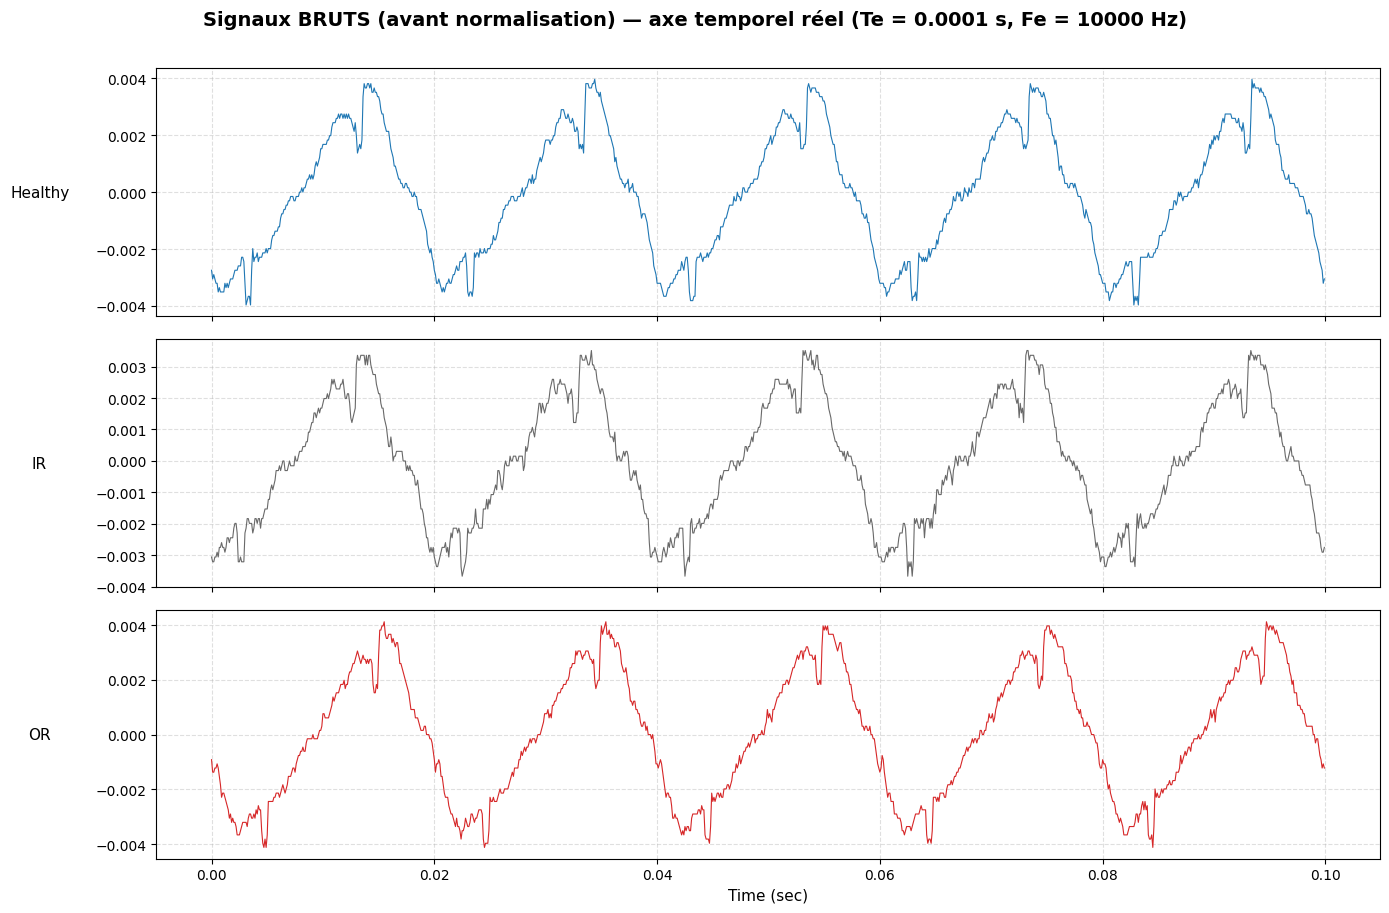

Figure 2 : Signaux bruts (axe temporel Te=0.0001 s) affichée.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# PARAMÈTRES
n_points = 1000          # Nombre d'échantillons à afficher
Fe = 10_000              # Fréquence d'échantillonnage : 10 kHz
Te = 1 / Fe              # Période d'échantillonnage : 0.0001 s

# Axe en indices (Figure 1)
indices = np.arange(n_points)
# Axe temporel réel (Figure 2)
temps = indices * Te     # en secondes

# Configuration des 3 modes
datasets_brut = [
    (df_normal, "Normal",        "tab:blue"),
    (df_irf,    "Inner Race Fault (IRF)", "tab:red"),
    (df_orf,    "Outer Race Fault (ORF)", "tab:green"),
]



fig2, axes2 = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig2.suptitle(f"Signaux BRUTS (avant normalisation) — axe temporel réel (Te = {Te:.4f} s, Fe = {Fe} Hz)",
              fontsize=14, fontweight='bold', y=1.01)

labels_ax2 = ["Healthy", "IR", "OR"]
colors_ax2 = ["tab:blue", "dimgray", "tab:red"]

for ax, (df, label, _), lbl, col in zip(axes2, datasets_brut, labels_ax2, colors_ax2):
    signal = df.iloc[0, :n_points].values
    ax.plot(temps, signal, color=col, linewidth=0.8)
    ax.set_ylabel(lbl, fontsize=11, rotation=0, labelpad=40, va='center')
    ax.set_ylim(auto=True)
    ax.grid(True, linestyle='--', alpha=0.4)
    # Bornes Y de 0 à 1 si données normalisées, sinon auto

axes2[-1].set_xlabel("Time (sec)", fontsize=11)
plt.tight_layout()
plt.savefig('fig2_brut_temps.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 2 : Signaux bruts (axe temporel Te={Te} s) affichée.")

---
### 📈 Visualisation APRÈS Normalisation (Min-Max [0, 1])
---

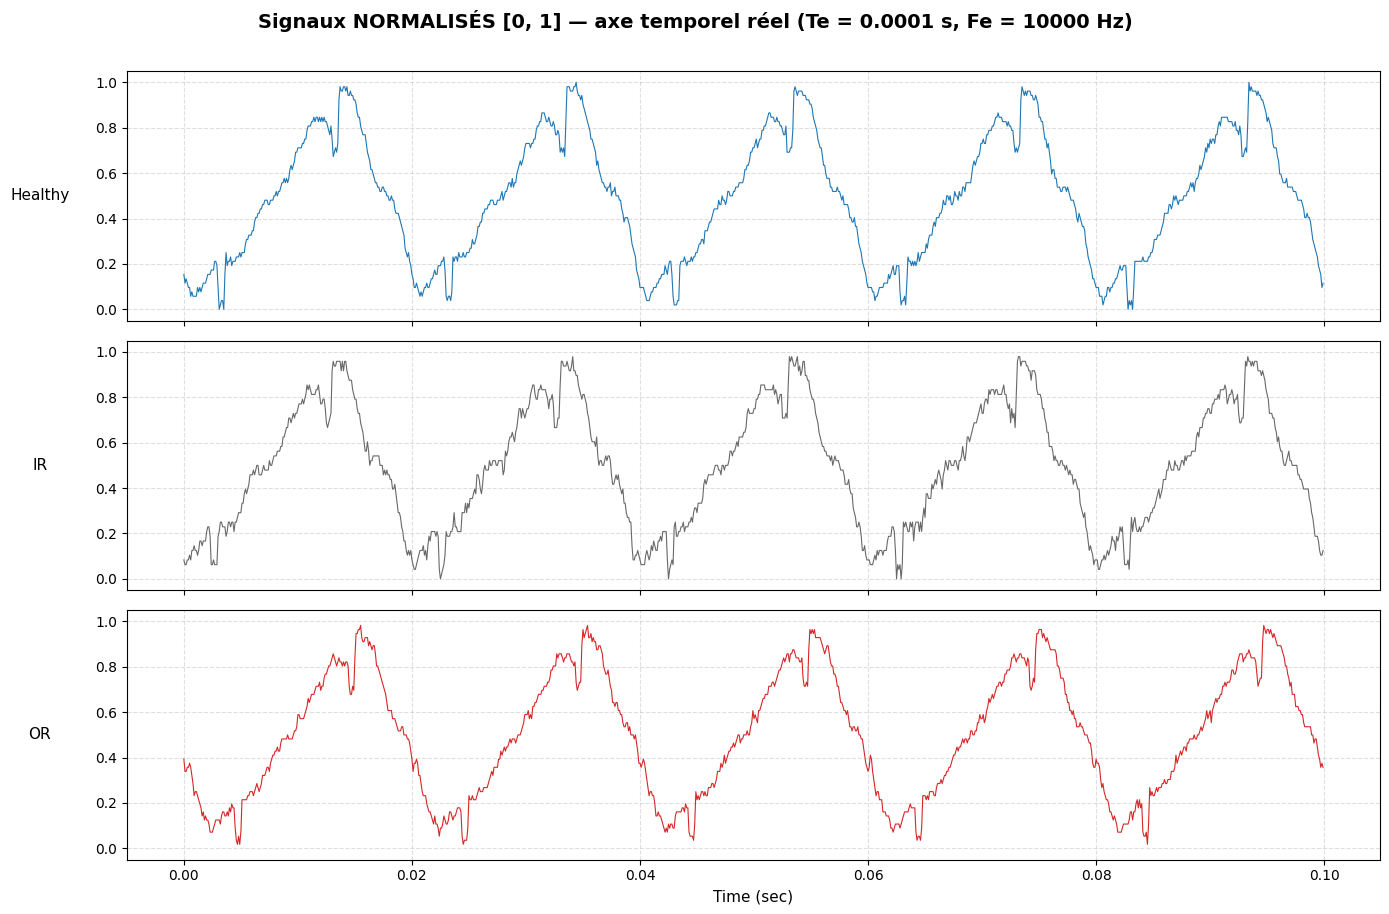

Figure 4 : Signaux normalisés (axe temporel Te=0.0001 s) affichée.


In [10]:
# PARAMÈTRES (mêmes que ci-dessus)
n_points = 1000
Fe = 10_000
Te = 1 / Fe
indices = np.arange(n_points)
temps   = indices * Te

datasets_norm = [
    (df_normal_norm, "Normal",                 "tab:blue"),
    (df_irf_norm,    "Inner Race Fault (IRF)",  "tab:red"),
    (df_orf_norm,    "Outer Race Fault (ORF)",  "tab:green"),
]



# FIGURE 4 — Signaux NORMALISÉS — axe temporel réel
fig4, axes4 = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig4.suptitle(f"Signaux NORMALISÉS [0, 1] — axe temporel réel (Te = {Te:.4f} s, Fe = {Fe} Hz)",
              fontsize=14, fontweight='bold', y=1.01)

labels_ax4 = ["Healthy", "IR", "OR"]
colors_ax4 = ["tab:blue", "dimgray", "tab:red"]

for ax, (df, label, _), lbl, col in zip(axes4, datasets_norm, labels_ax4, colors_ax4):
    signal = df.iloc[0, :n_points].values
    ax.plot(temps, signal, color=col, linewidth=0.8)
    ax.set_ylabel(lbl, fontsize=11, rotation=0, labelpad=40, va='center')
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle='--', alpha=0.4)

axes4[-1].set_xlabel("Time (sec)", fontsize=11)
plt.tight_layout()
plt.savefig('fig4_norm_temps.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Figure 4 : Signaux normalisés (axe temporel Te={Te} s) affichée.")

In [11]:
from google.colab import data_table

# Activer l'affichage interactif
data_table.enable_dataframe_formatter()

# Maintenant, quand tu appelles le dataframe, il sera interactif
df_irf_norm.head(100)

,0,1,2,3,4,5,6,7,8,9,...,4990,4991,4992,4993,4994,4995,4996,4997,4998,4999
0,0.083333,0.062500,0.062500,0.083333,0.083333,0.104167,0.083333,0.125000,0.125000,0.145833,...,0.395833,0.354167,0.333333,0.291667,0.270833,0.250000,0.229167,0.208333,0.208333,0.166667
1,0.187500,0.166667,0.145833,0.208333,0.208333,0.229167,0.125000,0.020833,0.041667,0.041667,...,0.229167,0.250000,0.229167,0.250000,0.229167,0.270833,0.291667,0.250000,0.250000,0.270833
2,0.740000,0.720000,0.740000,0.740000,0.760000,0.760000,0.760000,0.740000,0.760000,0.820000,...,0.820000,0.800000,0.820000,0.800000,0.780000,0.760000,0.820000,0.780000,0.680000,0.660000
3,0.711538,0.750000,0.750000,0.769231,0.942308,0.961538,0.961538,0.961538,1.000000,0.961538,...,0.480769,0.500000,0.480769,0.500000,0.500000,0.480769,0.500000,0.519231,0.519231,0.519231
4,0.510204,0.530612,0.530612,0.530612,0.551020,0.530612,0.551020,0.571429,0.571429,0.571429,...,0.795918,0.795918,0.775510,0.816327,0.836735,0.836735,0.836735,0.836735,0.877551,0.857143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.500000,0.480000,0.500000,0.480000,0.460000,0.500000,0.500000,0.500000,0.500000,0.520000,...,0.040000,0.060000,0.100000,0.140000,0.160000,0.160000,0.160000,0.140000,0.120000,0.180000
96,0.489796,0.489796,0.469388,0.469388,0.469388,0.469388,0.469388,0.489796,0.489796,0.489796,...,0.142857,0.040816,0.040816,0.040816,0.061224,0.020408,0.061224,0.224490,0.224490,0.224490
97,0.500000,0.500000,0.500000,0.520000,0.500000,0.520000,0.520000,0.560000,0.580000,0.580000,...,0.280000,0.280000,0.280000,0.300000,0.280000,0.320000,0.320000,0.340000,0.360000,0.360000
98,0.740000,0.780000,0.780000,0.800000,0.800000,0.800000,0.820000,0.820000,0.840000,0.860000,...,0.720000,0.720000,0.720000,0.720000,0.720000,0.740000,0.760000,0.760000,0.780000,0.800000


In [12]:
!pip install pyts

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 25.7 MB/s eta 0:00:00



--- Génération pour la taille : 224x224 ---


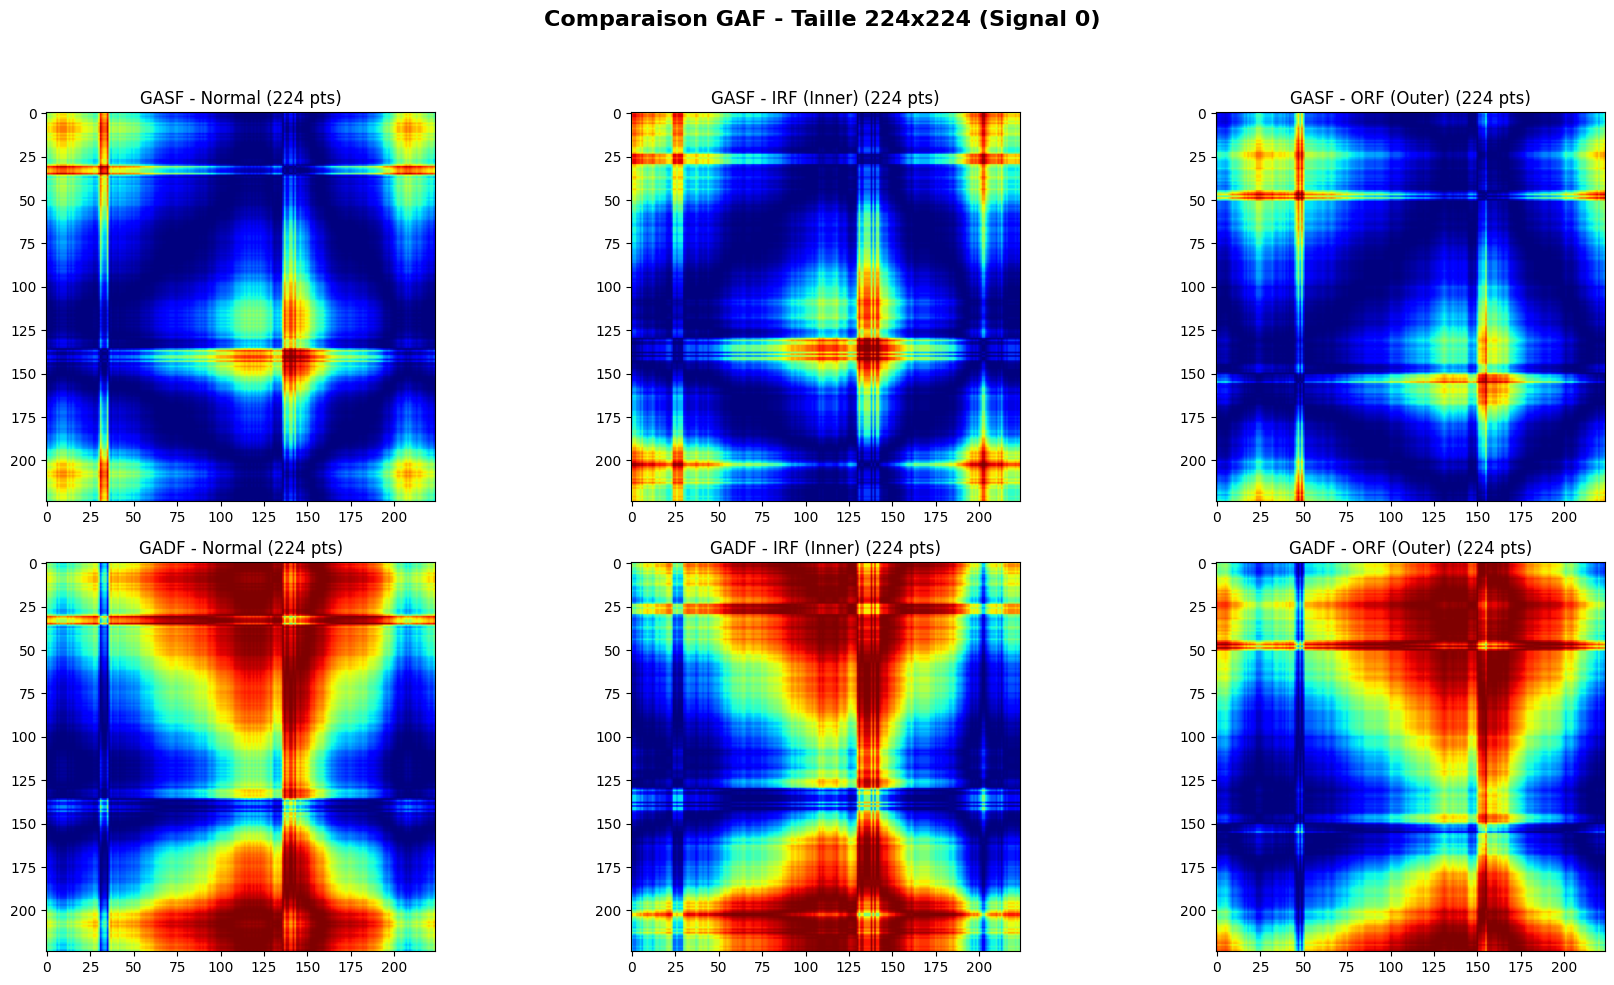


--- Génération pour la taille : 512x512 ---


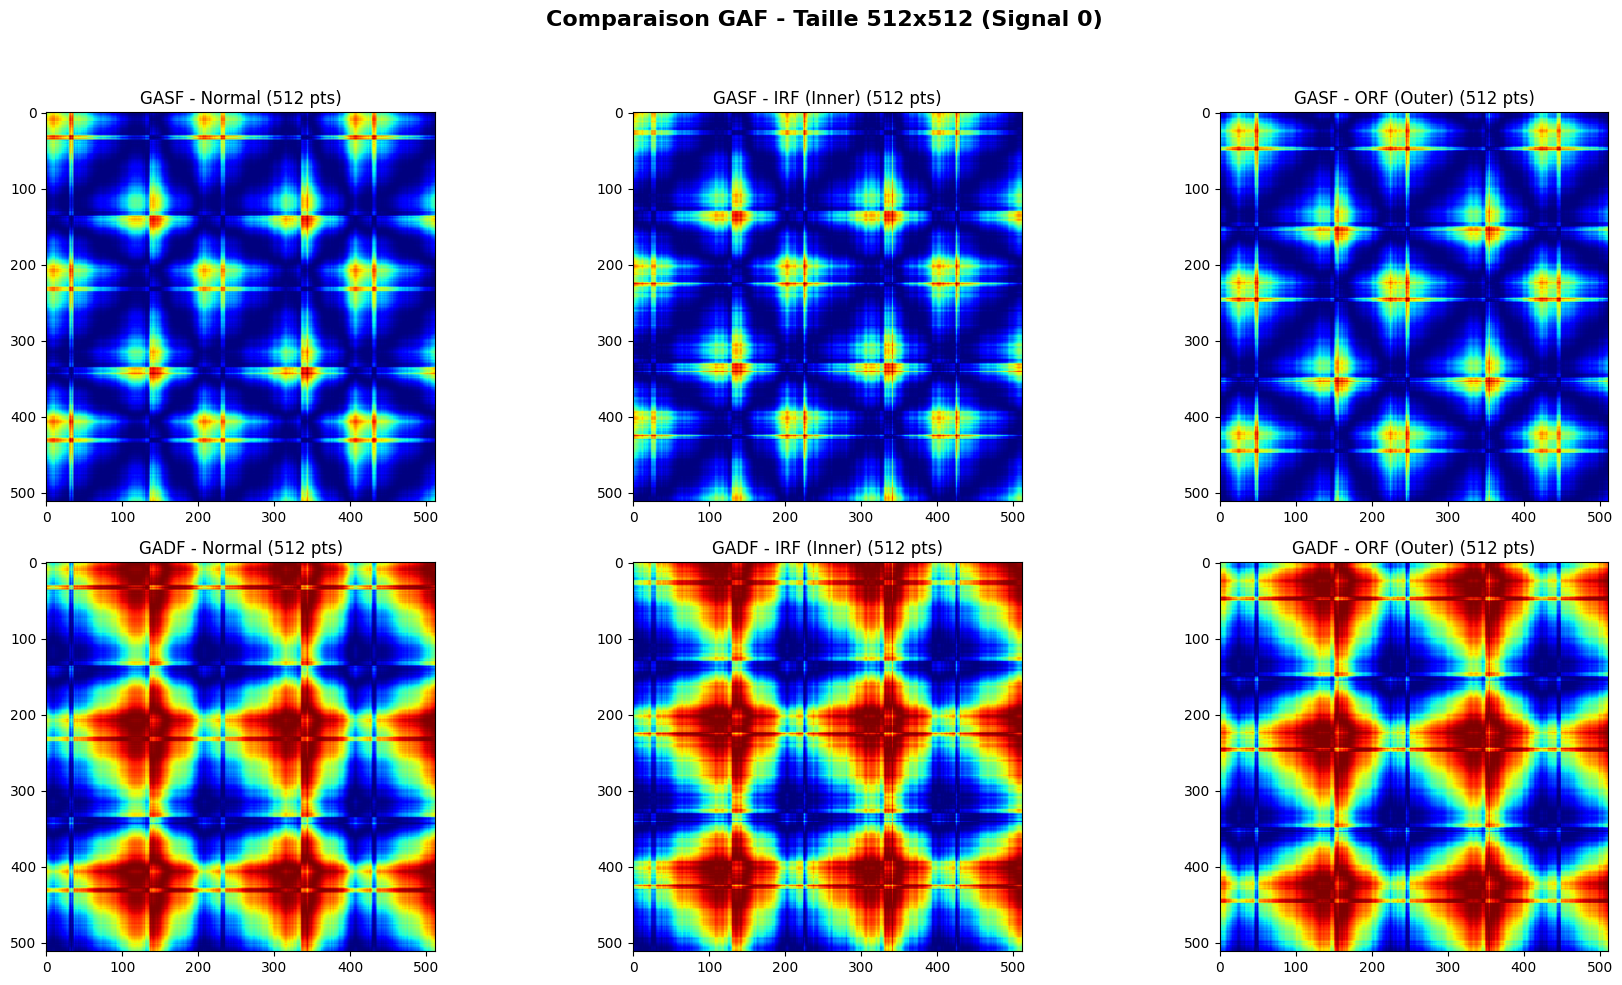


--- Génération pour la taille : 1000x1000 ---


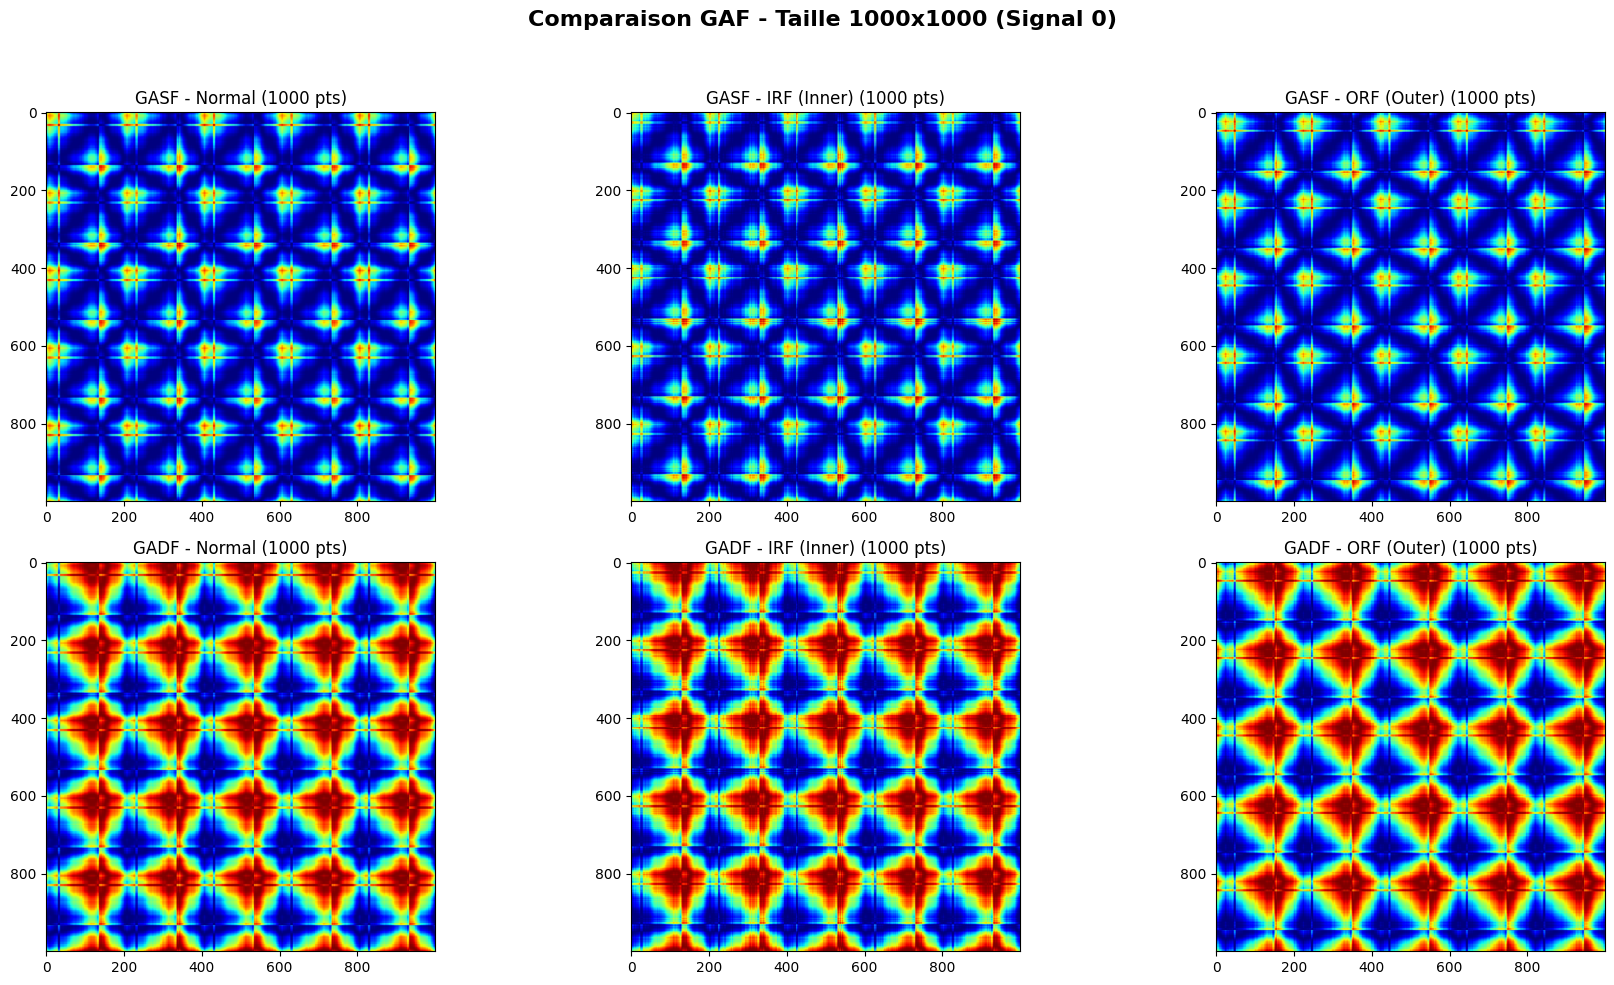


--- Génération pour la taille : 1024x1024 ---


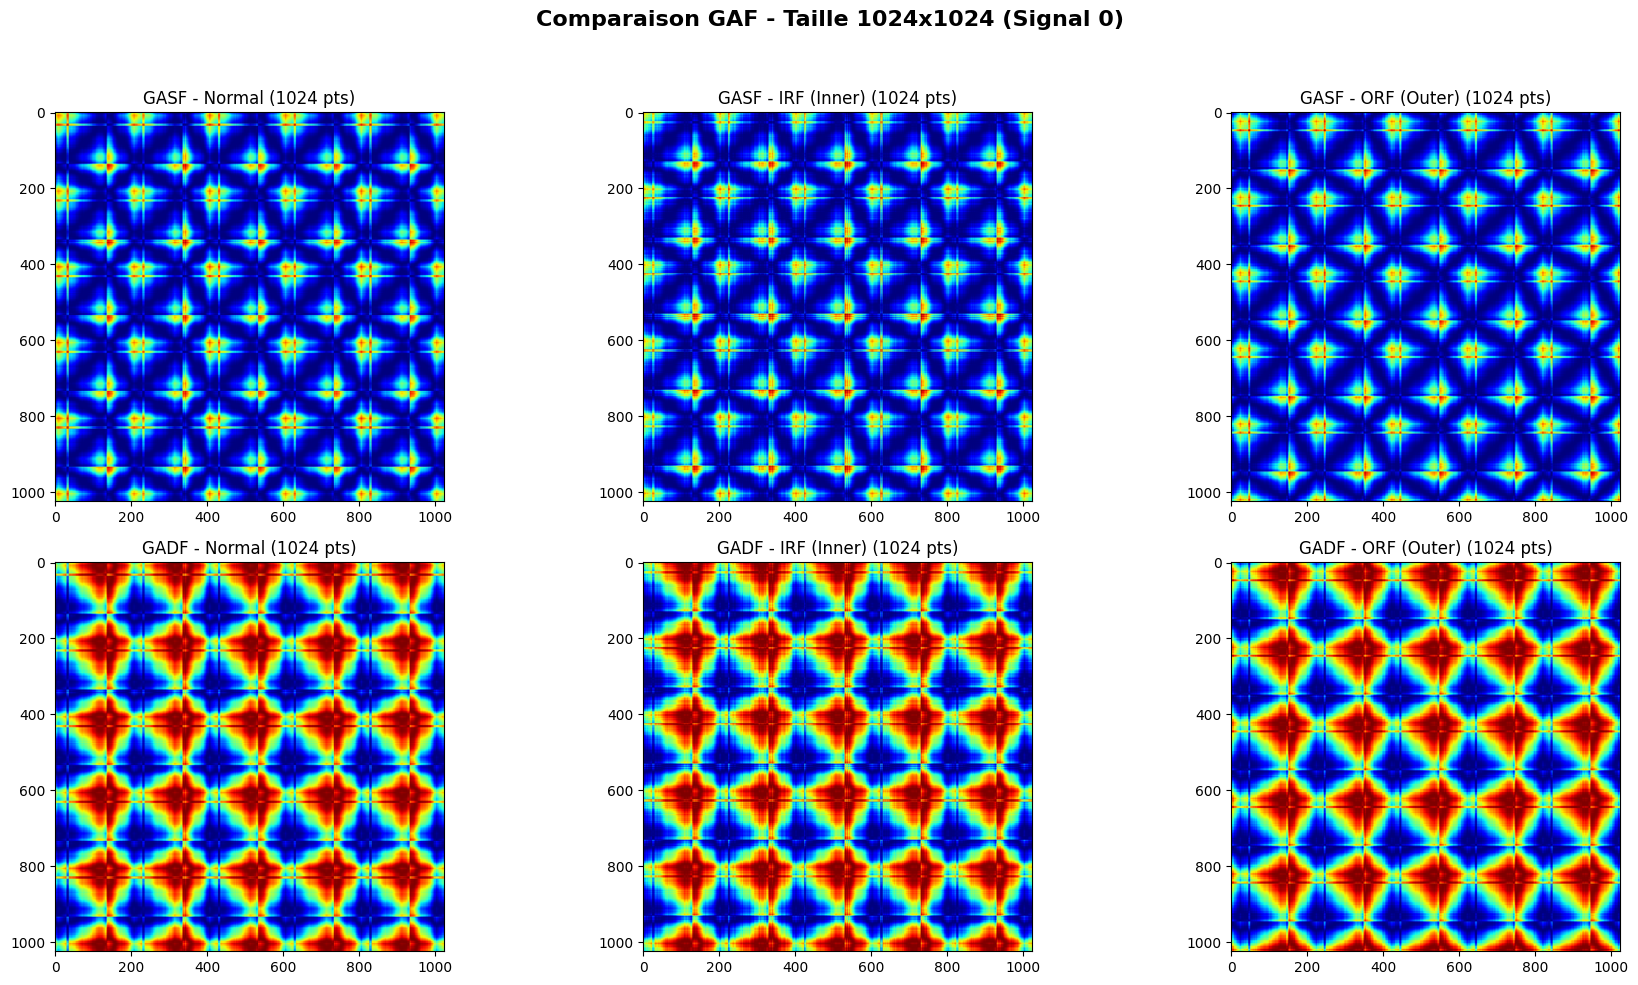

In [13]:
import matplotlib.pyplot as plt
from pyts.image import GramianAngularField

def tester_resolutions_gaf(signal_idx):

    # Liste des tailles à tester
    tailles_a_tester = [224, 512, 1000, 1024]

    # Préparation des données (on prend les 5000 premiers points pour couvrir toutes les tailles)
    n_max = 5000
    X_n = df_normal_norm.iloc[[signal_idx], :n_max].values
    X_i = df_irf_norm.iloc[[signal_idx], :n_max].values
    X_o = df_orf_norm.iloc[[signal_idx], :n_max].values

    data_1d = [X_n, X_i, X_o]
    labels = ["Normal", "IRF (Inner)", "ORF (Outer)"]

    for size in tailles_a_tester:
        print(f"\n--- Génération pour la taille : {size}x{size} ---")

        # Note : 'summation' pour GASF et 'difference' pour GADF
        gasf_gen = GramianAngularField(method='summation', image_size=size)
        gadf_gen = GramianAngularField(method='difference', image_size=size)

        # Création de la figure (2 lignes : GASF et GADF / 3 colonnes : les modes)
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle(f"Comparaison GAF - Taille {size}x{size} (Signal {signal_idx})",
                     fontsize=16, fontweight='bold')

        for col in range(3):
            # Calcul local pour éviter la saturation RAM
            img_gasf = gasf_gen.fit_transform(data_1d[col][:, :size])[0]
            img_gadf = gadf_gen.fit_transform(data_1d[col][:, :size])[0]

            # Affichage GASF (Ligne 0)
            axes[0, col].imshow(img_gasf, cmap='jet', origin='upper')
            axes[0, col].set_title(f"GASF - {labels[col]} ({size} pts)")

            # Affichage GADF (Ligne 1)
            axes[1, col].imshow(img_gadf, cmap='jet', origin='upper')
            axes[1, col].set_title(f"GADF - {labels[col]} ({size} pts)")

            # Affichage des axes pour vérifier la dimension
            axes[0, col].axis('on')
            axes[1, col].axis('on')

        plt.tight_layout(rect=[0, 0, 1, 0.95])
        plt.show()

        plt.close()

# Exécuter le test
tester_resolutions_gaf(signal_idx=0)

In [14]:
#  GÉNÉRATION + SAUVEGARDE ZIP


import os
import shutil
import zipfile
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from pyts.image import GramianAngularField
from google.colab import files

# CONFIGURATION
OUTPUT_ROOT = "/content/Export_GAF_Individuel"
ZIP_PATH    = "/content/Export_GAF_Individuel.zip"
TAILLES     = [512, 1024]
N_SIGNALS   = 100
N_MAX       = 5000

MODES = [
    ("Normal",     df_normal_norm),
    ("IRF",        df_irf_norm),
    ("ORF",        df_orf_norm),
]
METHODS = [
    ("GASF", "summation"),
    ("GADF", "difference"),
]

# Nettoyage
if os.path.exists(OUTPUT_ROOT):
    shutil.rmtree(OUTPUT_ROOT)
os.makedirs(OUTPUT_ROOT)

# 1. GÉNÉRATION DES IMAGES INDIVIDUELLES
total = 0
for size in TAILLES:
    print(f"\n{'='*60}")
    print(f"  Taille {size}x{size}")
    print(f"{'='*60}")

    # Initialisation des transformateurs (une seule fois par taille)
    gasf_gen = GramianAngularField(method='summation',  image_size=size)
    gadf_gen = GramianAngularField(method='difference', image_size=size)
    gaf_gens = {"GASF": gasf_gen, "GADF": gadf_gen}

    for mode_name, df_norm in MODES:
        for method_label, _ in METHODS:
            gaf_gen = gaf_gens[method_label]

            # Dossier : Export/GAF_512/Normal/GASF/
            save_dir = os.path.join(OUTPUT_ROOT, f"GAF_{size}", mode_name, method_label)
            os.makedirs(save_dir, exist_ok=True)

            # Transformer tous les 100 signaux d'un coup
            X = df_norm.iloc[:N_SIGNALS, :size].values   # (100, size)
            images = gaf_gen.fit_transform(X)             # (100, size, size)

            for idx in range(N_SIGNALS):
                # Image pure : sans axes, sans titre, sans bordure
                fig, ax = plt.subplots(1, 1, figsize=(size/100, size/100), dpi=100)
                ax.imshow(images[idx], cmap='jet', origin='upper')
                ax.axis('off')
                plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

                img_path = os.path.join(save_dir, f"signal_{idx:03d}.png")
                plt.savefig(img_path, dpi=100, bbox_inches='tight', pad_inches=0)
                plt.close(fig)
                total += 1

            print(f"  ✅ {size}x{size} | {mode_name:6s} | {method_label} — {N_SIGNALS} images")

print(f"\n✅ Total images générées : {total}")

#  SAUVEGARDE DES CSV
print("\n📄 Sauvegarde des CSV...")
csv_dir = os.path.join(OUTPUT_ROOT, "CSV")
os.makedirs(os.path.join(csv_dir, "Non_Normalises"), exist_ok=True)
os.makedirs(os.path.join(csv_dir, "Normalises"),     exist_ok=True)

for df, fname in [(df_normal, "base_normal.csv"),
                  (df_irf,    "base_irf.csv"),
                  (df_orf,    "base_orf.csv")]:
    df.to_csv(os.path.join(csv_dir, "Non_Normalises", fname), index=False)
    print(f"  ✅ [Non normalisé] {fname}")

for df, fname in [(df_normal_norm, "Base_1D_Normal_normalized.csv"),
                  (df_irf_norm,    "Base_1D_IRF_normalized.csv"),
                  (df_orf_norm,    "Base_1D_ORF_normalized.csv")]:
    df.to_csv(os.path.join(csv_dir, "Normalises", fname), index=False)
    print(f"  ✅ [Normalisé]     {fname}")

# CRÉATION DU ZIP
print("\n🗜️  Création du ZIP...")
with zipfile.ZipFile(ZIP_PATH, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for dirpath, dirnames, filenames in os.walk(OUTPUT_ROOT):
        for filename in filenames:
            filepath = os.path.join(dirpath, filename)
            arcname  = os.path.relpath(filepath, OUTPUT_ROOT)
            zf.write(filepath, arcname)

zip_mb = os.path.getsize(ZIP_PATH) / (1024 * 1024)
print(f"\n✅ ZIP : {ZIP_PATH}  ({zip_mb:.1f} Mo)")
print(f"\n📊 Résumé :")
print(f"   • 2 tailles × 3 modes × 2 méthodes × 100 signaux = {total} images PNG")
print(f"   • 6 fichiers CSV (3 normalisés + 3 non normalisés)")
print(f"\nStructure du ZIP :")
print(f"   GAF_512/")
print(f"     Normal/GASF/signal_000.png ... signal_099.png  (100 img)")
print(f"     Normal/GADF/signal_000.png ... signal_099.png  (100 img)")
print(f"     IRF/GASF/   ORF/GASF/   IRF/GADF/   ORF/GADF/ ...")
print(f"   GAF_1024/   (même structure)")
print(f"   CSV/Non_Normalises/   CSV/Normalises/")

# ----------------------------------------------------------
# 4. TÉLÉCHARGEMENT
# ----------------------------------------------------------
print("\n⬇️  Téléchargement en cours...")
files.download(ZIP_PATH)
print("✅ Téléchargement lancé !")



  Taille 512x512
  ✅ 512x512 | Normal | GASF — 100 images
  ✅ 512x512 | Normal | GADF — 100 images
  ✅ 512x512 | IRF    | GASF — 100 images
  ✅ 512x512 | IRF    | GADF — 100 images
  ✅ 512x512 | ORF    | GASF — 100 images
  ✅ 512x512 | ORF    | GADF — 100 images

  Taille 1024x1024
  ✅ 1024x1024 | Normal | GASF — 100 images
  ✅ 1024x1024 | Normal | GADF — 100 images
  ✅ 1024x1024 | IRF    | GASF — 100 images
  ✅ 1024x1024 | IRF    | GADF — 100 images
  ✅ 1024x1024 | ORF    | GASF — 100 images
  ✅ 1024x1024 | ORF    | GADF — 100 images

✅ Total images générées : 1200

📄 Sauvegarde des CSV...
  ✅ [Non normalisé] base_normal.csv
  ✅ [Non normalisé] base_irf.csv
  ✅ [Non normalisé] base_orf.csv
  ✅ [Normalisé]     Base_1D_Normal_normalized.csv
  ✅ [Normalisé]     Base_1D_IRF_normalized.csv
  ✅ [Normalisé]     Base_1D_ORF_normalized.csv

🗜️  Création du ZIP...

✅ ZIP : /content/Export_GAF_Individuel.zip  (382.2 Mo)

📊 Résumé :
   • 2 tailles × 3 modes × 2 méthodes × 100 signaux = 1200 imag

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Téléchargement lancé !
